In [2]:
# Install Dependecies

!pip install -qqqq -U langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.2/250.2 kB 5.1 MB/s eta 0:00:00


In [6]:
# Import Dependencies

from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import display,Image


In [9]:
# ==========================================
# 1. DEFINE States
# ==========================================

class State(TypedDict):
    topic: str
    result: str
    user_decision: str  # Field to store the interrupt response

In [29]:
# ==========================================
# 2. DEFINE Nodes
# ==========================================

def review_and_execute_node(state: State):
    # 1. Capture the resume value directly from interrupt()
    decision = interrupt(f"Do you approve writing about {state['topic']}?")
    # 2. Use the local variable directly
    if decision == "yes":
        return {"result": "Approved and executed!"}
    return {"result": "Action rejected."}

def review_node(state: State):
    # 1. Pause and get input from interrupt()
    decision = interrupt(f"Do you approve writing about {state['topic']}?")
    # 2. Store the input explicitly into the graph state
    return {"user_decision": decision}

def execution_node(state: State):
    # 3. Retrieve the value from the state using state.get()
    decision = state.get("user_decision")
    if decision == "yes":
        return {"result": "Approved and executed!"}
    return {"result": "Action rejected."}

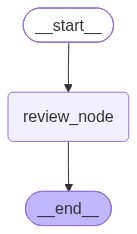

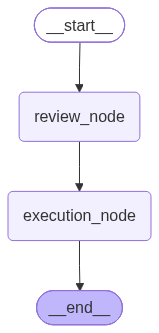

In [30]:
# ==========================================
# 3. DEFINE Graph
# ==========================================

# Build workflow for review_and_execute_node
workflow_4_review_and_execute_together = StateGraph(State)
workflow_4_review_and_execute_seperate = StateGraph(State)

# Add node for review_and_execute_node
workflow_4_review_and_execute_together.add_node("review_node", review_and_execute_node)
workflow_4_review_and_execute_seperate.add_node("review_node", review_node)
workflow_4_review_and_execute_seperate.add_node("execution_node", execution_node)

# Add edge for review_and_execute_node
workflow_4_review_and_execute_together.add_edge(START, "review_node")
workflow_4_review_and_execute_together.add_edge("review_node", END)
workflow_4_review_and_execute_seperate.add_edge(START, "review_node")
workflow_4_review_and_execute_seperate.add_edge("review_node", "execution_node")
workflow_4_review_and_execute_seperate.add_edge("execution_node", END)


# Build graph for review_and_execute_node
graph_4_review_and_execute_together = workflow_4_review_and_execute_together.compile(checkpointer=MemorySaver())
graph_4_review_and_execute_seperate = workflow_4_review_and_execute_seperate.compile(checkpointer=MemorySaver())

# View graph for review_and_execute_node
display(Image(graph_4_review_and_execute_together.get_graph().draw_mermaid_png()))
display(Image(graph_4_review_and_execute_seperate.get_graph().draw_mermaid_png()))

In [32]:
# ==========================================
# 4. Execute Graph
# ==========================================

# Set up Threads
config1 = {"configurable": {"thread_id": "thread-1"}}
config2 = {"configurable": {"thread_id": "thread-2"}}

# Run the graph and expects interupt
try:
    output_4_review_and_execute_together1 = graph_4_review_and_execute_together.invoke({"topic": "AI Agents", "result": ""}, config1)
    output_4_review_and_execute_together2 = graph_4_review_and_execute_together.invoke({"topic": "AI Agents", "result": ""}, config2)
    output_4_review_and_execute_seperate1 = graph_4_review_and_execute_seperate.invoke({"topic": "AI Agents", "user_decision": "", "result": ""}, config1)
    output_4_review_and_execute_seperate2 = graph_4_review_and_execute_seperate.invoke({"topic": "AI Agents", "user_decision": "", "result": ""}, config2)
except Exception:
    pass  # Pauses at interrupt

print("\n============================================================")
print("Example 1 Output for review_and_execute_together before interrupt:", output_4_review_and_execute_together1)
print("Example 1 Output for review_and_execute_seperate before interrupt:", output_4_review_and_execute_seperate1)
print("Example 2 Output for review_and_execute_together before interrupt:", output_4_review_and_execute_together2)
print("Example 2 Output for review_and_execute_seperate before interrupt:", output_4_review_and_execute_seperate2)
print("\n============================================================")

# Resume the graph after interupt
output_4_review_and_execute_together1 = graph_4_review_and_execute_together.invoke(Command(resume="yes"), config=config1)
output_4_review_and_execute_together2 = graph_4_review_and_execute_together.invoke(Command(resume="no"), config=config2)
output_4_review_and_execute_seperate1 = graph_4_review_and_execute_seperate.invoke(Command(resume="yes"), config=config1)
output_4_review_and_execute_seperate2 = graph_4_review_and_execute_seperate.invoke(Command(resume="no"), config=config2)


# Print the output
print("\n============================================================")
print("Example 1 Output for review_and_execute_together after interrupt:", output_4_review_and_execute_together1)
print("Example 1 Output for review_and_execute_seperate after interrupt:", output_4_review_and_execute_seperate1)
print("Example 2 Output for review_and_execute_together after interrupt:", output_4_review_and_execute_together2)
print("Example 2 Output for review_and_execute_seperate after interrupt:", output_4_review_and_execute_seperate2)
print("\n============================================================")


Example 1 Output for review_and_execute_together before interrupt: {'topic': 'AI Agents', 'result': '', '__interrupt__': [Interrupt(value='Do you approve writing about AI Agents?', id='9a6df87ac6c27603863459ab852eaddc', response_schema=None)]}
Example 1 Output for review_and_execute_seperate before interrupt: {'topic': 'AI Agents', 'result': '', 'user_decision': '', '__interrupt__': [Interrupt(value='Do you approve writing about AI Agents?', id='352e5ee816c1e4dd2135bff5f5a632cc', response_schema=None)]}
Example 2 Output for review_and_execute_together before interrupt: {'topic': 'AI Agents', 'result': '', '__interrupt__': [Interrupt(value='Do you approve writing about AI Agents?', id='d99ec2e16efcd253cbffb1c10b3fad30', response_schema=None)]}
Example 2 Output for review_and_execute_seperate before interrupt: {'topic': 'AI Agents', 'result': '', 'user_decision': '', '__interrupt__': [Interrupt(value='Do you approve writing about AI Agents?', id='aeafbe512615aeabbe1fc6ab86199e39', respo